In [2]:
# Install required package
!pip install nba_api

import json
import time
import pandas as pd
import requests
from datetime import datetime
import pytz
from nba_api.stats.endpoints import teamestimatedmetrics
from nba_api.stats.endpoints import leaguedashteamstats, commonteamroster
from nba_api.stats.static import teams
from nba_api.stats.endpoints import playergamelog
from nba_api.stats.library.parameters import SeasonAll
from IPython.display import display

# Map of team names to abbreviations
TEAM_NAME_TO_ABBREVIATION = {
    "Atlanta Hawks": "ATL", "Boston Celtics": "BOS", "Brooklyn Nets": "BKN",
    "Charlotte Hornets": "CHA", "Chicago Bulls": "CHI", "Cleveland Cavaliers": "CLE",
    "Dallas Mavericks": "DAL", "Denver Nuggets": "DEN", "Detroit Pistons": "DET",
    "Golden State Warriors": "GSW", "Houston Rockets": "HOU", "Indiana Pacers": "IND",
    "LA Clippers": "LAC", "Los Angeles Lakers": "LAL", "Memphis Grizzlies": "MEM",
    "Miami Heat": "MIA", "Milwaukee Bucks": "MIL", "Minnesota Timberwolves": "MIN",
    "New Orleans Pelicans": "NOP", "New York Knicks": "NYK", "Oklahoma City Thunder": "OKC",
    "Orlando Magic": "ORL", "Philadelphia 76ers": "PHI", "Phoenix Suns": "PHX",
    "Portland Trail Blazers": "POR", "Sacramento Kings": "SAC", "San Antonio Spurs": "SAS",
    "Toronto Raptors": "TOR", "Utah Jazz": "UTA", "Washington Wizards": "WAS"
}

# Set display options for Google Colab
pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.max_columns', None)  # Show all columns
pd.set_option('display.expand_frame_repr', False)
pd.set_option('max_colwidth', None)

# Fetch today's schedule from NBA Stats API
def fetch_schedule():
    try:
        url = "https://data.nba.com/data/10s/v2015/json/mobile_teams/nba/2024/league/00_full_schedule.json"
        response = requests.get(url)
        response.raise_for_status()
        data = response.json()

        est = pytz.timezone('US/Eastern')
        today = datetime.now(est).strftime('%Y-%m-%d')
        games_today = []

        for month_data in data['lscd']:
            for game in month_data['mscd']['g']:
                if game['gdte'] == today:
                    games_today.append({
                        'home_team': game['h']['ta'],
                        'away_team': game['v']['ta'],
                        'home_team_id': game['h']['tid'],
                        'away_team_id': game['v']['tid']
                    })

        if not games_today:
            print(f"No games scheduled for {today}.")
        return games_today
    except Exception as e:
        print(f"Error fetching schedule: {e}")
        return []

# Fetch team metrics
def fetch_team_metrics():
    try:
        stats = teamestimatedmetrics.TeamEstimatedMetrics(
            season="2024-25", season_type="Regular Season", league_id="00"
        ).get_data_frames()[0]

        metrics = stats[['TEAM_NAME', 'E_OFF_RATING', 'E_DEF_RATING', 'E_PACE']]
        metrics_dict = metrics.set_index('TEAM_NAME').to_dict(orient='index')

        avg_pace = metrics['E_PACE'].mean()
        avg_off_rating = metrics['E_OFF_RATING'].mean()
        avg_def_rating = metrics['E_DEF_RATING'].mean()

        team_metrics = {TEAM_NAME_TO_ABBREVIATION.get(k, k): v for k, v in metrics_dict.items()}
        return team_metrics, avg_pace, avg_off_rating, avg_def_rating
    except Exception as e:
        print(f"Error fetching team metrics: {e}")
        return {}, 0, 0, 0

# Initialize DvP data
def initialize_dvp_data():
    try:
        stats = leaguedashteamstats.LeagueDashTeamStats(
            measure_type_detailed_defense='Opponent',
            per_mode_detailed='PerGame',
            season="2024-25",
            season_type_all_star="Regular Season"
        ).get_data_frames()[0]

        stats['TEAM_ABBREVIATION'] = stats['TEAM_NAME'].map(TEAM_NAME_TO_ABBREVIATION)

        dvp_data = {}
        for pos in ['C', 'F', 'G']:
            column = f'OPP_PTS_{pos.upper()}'
            if column in stats.columns:
                dvp_data[pos] = stats.groupby('TEAM_ABBREVIATION')[column].mean().to_dict()

        return dvp_data
    except Exception as e:
        print(f"Error fetching DvP stats: {e}")
        return {}

# Fetch player game logs
def fetch_player_game_logs(player_id):
    try:
        return playergamelog.PlayerGameLog(player_id=player_id, season="2024-25").get_data_frames()[0]
    except Exception as e:
        print(f"Error fetching game logs for player {player_id}: {e}")
        return pd.DataFrame()

# Calculate stats
def calculate_stats(stat_series):
    mean = stat_series.mean()
    std_dev = stat_series.std()
    cv = std_dev / mean if mean != 0 else 0
    return mean, std_dev, cv

# Adjust predictions for DvP and other factors
def adjust_prediction(stat_mean, team_metrics, opposing_metrics, avg_pace, avg_off_rating, avg_def_rating, player_position, dvp_data):
    try:
        positions = player_position.split("-")
        dvp_factors = [dvp_data[pos].get(opposing_metrics['TEAM_ABBREVIATION'], 1) for pos in positions if pos in dvp_data]

        dvp_factor = sum(dvp_factors) / len(dvp_factors) if dvp_factors else 1
        pace_factor = team_metrics.get('E_PACE', avg_pace) / avg_pace if avg_pace != 0 else 1
        offensive_factor = team_metrics.get('E_OFF_RATING', avg_off_rating) / avg_off_rating if avg_off_rating != 0 else 1
        defensive_factor = opposing_metrics.get('E_DEF_RATING', avg_def_rating) / avg_def_rating if avg_def_rating != 0 else 1

        return stat_mean * pace_factor * offensive_factor / defensive_factor * dvp_factor
    except Exception as e:
        print(f"Error adjusting prediction: {e}")
        return stat_mean

# Analyze teams and players for today's games
def analyze_teams_for_today():
    dvp_data = initialize_dvp_data()
    games_today = fetch_schedule()
    team_metrics, avg_pace, avg_off_rating, avg_def_rating = fetch_team_metrics()

    if not games_today:
        print("No games scheduled for today.")
        return pd.DataFrame()

    all_players_data = []
    for game in games_today:
        home_team = game['home_team']
        away_team = game['away_team']

        if home_team not in team_metrics or away_team not in team_metrics:
            print(f"Metrics not available for one or both teams: {home_team}, {away_team}. Skipping game.")
            continue

        for team_name, opposing_metrics in [(home_team, team_metrics[away_team]), (away_team, team_metrics[home_team])]:
            try:
                team_id = teams.find_team_by_abbreviation(team_name)['id']
                roster = commonteamroster.CommonTeamRoster(team_id=team_id).get_data_frames()[0]

                for _, player in roster.iterrows():
                    player_id = player['PLAYER_ID']
                    player_name = player['PLAYER']
                    player_position = player['POSITION']

                    game_logs = fetch_player_game_logs(player_id)
                    if game_logs.empty:
                        continue

                    mean_ppg, std_dev_ppg, cv_ppg = calculate_stats(game_logs['PTS'])
                    mean_rpg, std_dev_rpg, cv_rpg = calculate_stats(game_logs['REB'])
                    mean_apg, std_dev_apg, cv_apg = calculate_stats(game_logs['AST'])

                    adjusted_ppg = adjust_prediction(mean_ppg, team_metrics[team_name], opposing_metrics, avg_pace, avg_off_rating, avg_def_rating, player_position, dvp_data)
                    adjusted_rpg = adjust_prediction(mean_rpg, team_metrics[team_name], opposing_metrics, avg_pace, avg_off_rating, avg_def_rating, player_position, dvp_data)
                    adjusted_apg = adjust_prediction(mean_apg, team_metrics[team_name], opposing_metrics, avg_pace, avg_off_rating, avg_def_rating, player_position, dvp_data)

                    # Add new difference columns
                    ppg_diff = mean_ppg - std_dev_ppg
                    rpg_diff = mean_rpg - std_dev_rpg
                    apg_diff = mean_apg - std_dev_apg

                    all_players_data.append({
                        'Player': player_name,
                        'Team': team_name,
                        'PPG': round(mean_ppg, 2),
                        'PPG SD': round(std_dev_ppg, 2),
                        'PPG CV': round(cv_ppg, 2),
                        'PPG Diff': round(ppg_diff, 2),  # Added PPG Diff
                        'Adj PPG': round(adjusted_ppg, 2),
                        'RPG': round(mean_rpg, 2),
                        'RPG SD': round(std_dev_rpg, 2),
                        'RPG CV': round(cv_rpg, 2),
                        'RPG Diff': round(rpg_diff, 2),  # Added RPG Diff
                        'Adj RPG': round(adjusted_rpg, 2),
                        'APG': round(mean_apg, 2),
                        'APG SD': round(std_dev_apg, 2),
                        'APG CV': round(cv_apg, 2),
                        'APG Diff': round(apg_diff, 2),  # Added APG Diff
                        'Adj APG': round(adjusted_apg, 2)
                    })

                    time.sleep(1)
            except Exception as e:
                print(f"Error analyzing team {team_name}: {e}")
                continue

    df = pd.DataFrame(all_players_data)
    display(df)
    return df

# Start the analysis
analyze_teams_for_today()

from google.colab import data_table
data_table.disable_dataframe_formatter()


,Player,Team,PPG,PPG SD,PPG CV,PPG Diff,Adj PPG,RPG,RPG SD,RPG CV,RPG Diff,Adj RPG,APG,APG SD,APG CV,APG Diff,Adj APG
0,Coby White,CHI,18.32,7.52,0.41,10.79,19.67,3.73,2.33,0.63,1.39,4.00,4.73,2.03,0.43,2.70,5.08
1,Lonzo Ball,CHI,5.14,2.27,0.44,2.88,5.52,2.43,1.40,0.58,1.03,2.61,3.57,1.72,0.48,1.85,3.84
2,Josh Giddey,CHI,11.83,4.66,0.39,7.17,12.71,6.17,3.13,0.51,3.04,6.62,6.71,2.74,0.41,3.97,7.21
3,Jevon Carter,CHI,1.64,2.69,1.65,-1.06,1.76,0.73,1.01,1.39,-0.28,0.78,0.55,0.69,1.26,-0.14,0.59
4,Jalen Smith,CHI,7.86,4.22,0.54,3.63,8.44,5.14,1.77,0.34,3.37,5.52,0.71,0.78,1.10,-0.07,0.77
5,Zach LaVine,CHI,21.76,7.66,0.35,14.10,23.37,4.43,2.79,0.63,1.64,4.76,4.29,2.88,0.67,1.40,4.60
6,Nikola Vučević,CHI,21.33,6.51,0.30,14.83,22.91,9.83,2.41,0.24,7.43,10.56,3.25,1.39,0.43,1.86,3.49
7,Ayo Dosunmu,CHI,12.79,6.32,0.49,6.47,13.74,3.79,2.23,0.59,1.57,4.07,4.54,2.08,0.46,2.46,4.88
8,Torrey Craig,CHI,5.17,6.49,1.26,-1.33,5.55,2.17,2.23,1.03,-0.06,2.33,0.50,0.84,1.67,-0.34,0.54
9,Matas Buzelis,CHI,5.35,5.60,1.05,-0.25,5.74,2.52,2.25,0.89,0.27,2.71,0.39,0.78,2.00,-0.39,0.42


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 279.4/279.4 kB 3.9 MB/s eta 0:00:00
Paste your CSV data below (then press Enter twice):
index,Player,Team,PPG,PPG SD,PPG CV,PPG Diff,Adj PPG,RPG,RPG SD,RPG CV,RPG Diff,Adj RPG,APG,APG SD,APG CV,APG Diff,Adj APG 0,Miles Bridges,CHA,16.0,7.36,0.46,8.64,15.41,6.55,2.11,0.32,4.43,6.3,3.0,2.1,0.7,0.9,2.89 1,LaMelo Ball,CHA,31.06,9.01,0.29,22.04,29.91,5.39,2.75,0.51,2.64,5.19,6.94,2.51,0.36,4.44,6.69 2,Grant Williams,CHA,10.38,4.43,0.43,5.95,9.99,5.12,2.39,0.47,2.73,4.94,2.31,1.54,0.66,0.78,2.23 3,DaQuan Jeffries,CHA,12.5,6.36,0.51,6.14,12.04,3.5,3.54,1.01,-0.04,3.37,1.0,0.0,0.0,1.0,0.96 4,Nick Richards,CHA,11.88,7.9,0.67,3.97,11.44,9.75,4.1,0.42,5.65,9.39,1.88,1.13,0.6,0.75,1.81 5,Mark Williams,CHA,7.33,4.16,0.57,3.17,7.06,4.33,1.15,0.27,3.18,4.17,1.0,1.0,1.0,0.0,0.96 6,Nick Smith Jr.,CHA,3.33,2.87,0.86,0.46,3.21,0.75,0.97,1.29,-0.22,0.72,0.75,0.97,1.29,-0.22,0.72 7,Josh Green,CHA,7.43,5.86,0.79,1.57,7.15,2.57,1.47,0.57,1.1,2.48,1.71,1.55,0.91,0.1

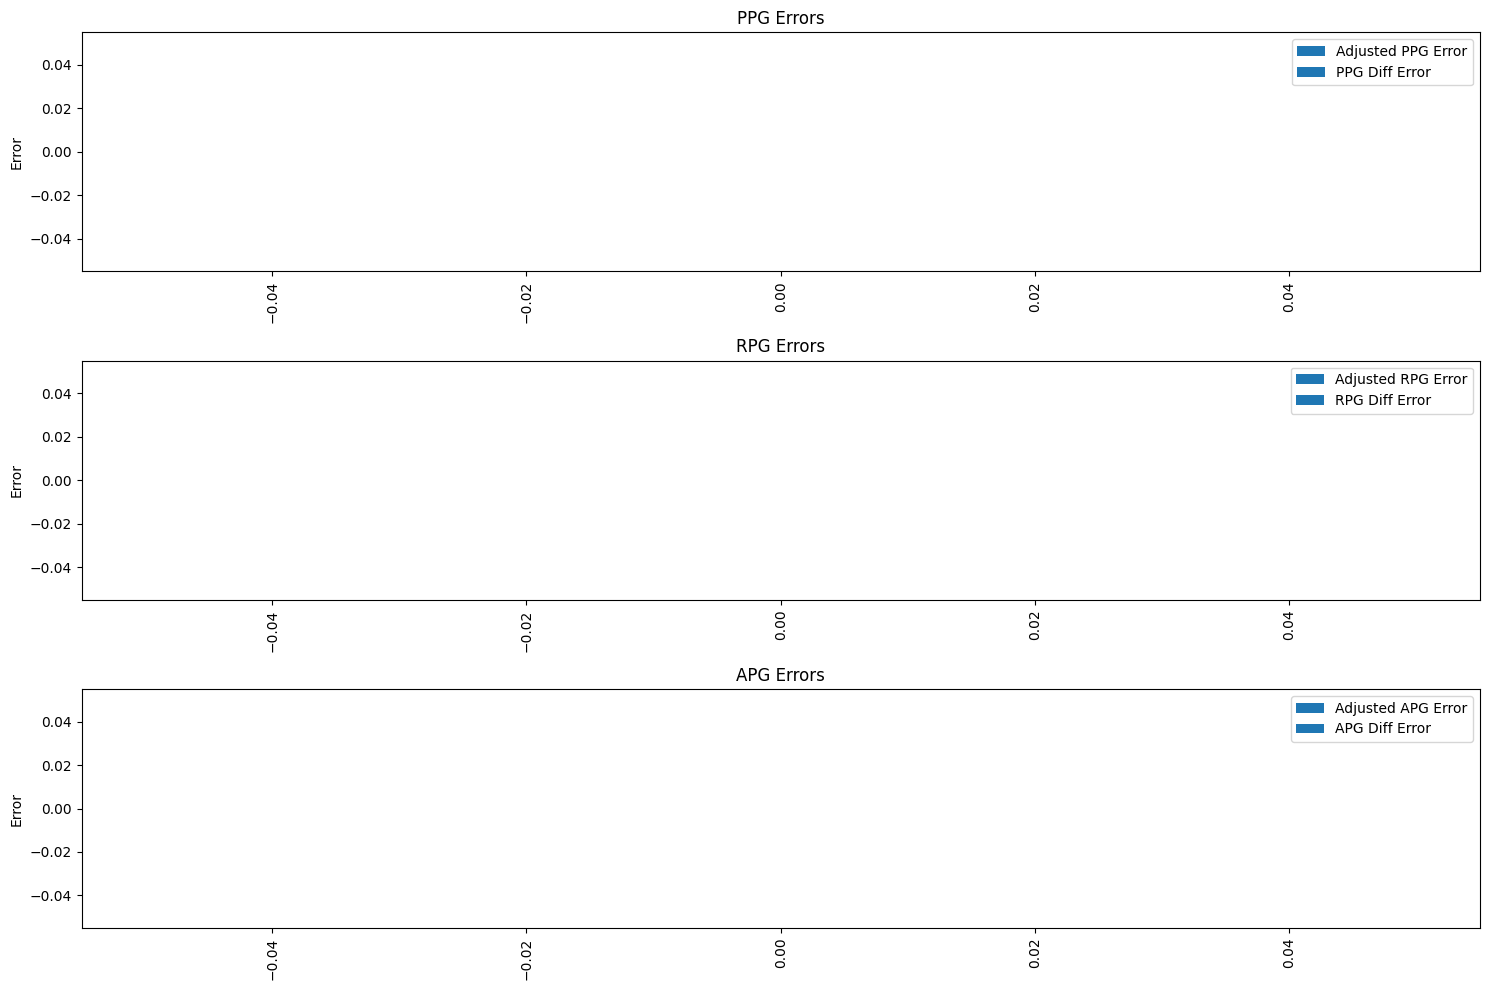

In [1]:
# Install nba_api
!pip install nba_api

import pandas as pd
import matplotlib.pyplot as plt
import io
from nba_api.stats.endpoints import scoreboardv2, boxscoretraditionalv2
from datetime import datetime, timedelta

# Function to get yesterday's date
def get_yesterday():
    return (datetime.now() - timedelta(days=1)).strftime('%Y-%m-%d')

# Function to fetch yesterday's game IDs
def get_yesterdays_game_ids():
    yesterday = get_yesterday()
    scoreboard = scoreboardv2.ScoreboardV2(game_date=yesterday)
    games = scoreboard.get_normalized_dict()['GameHeader']
    return [game['GAME_ID'] for game in games]

# Function to fetch box scores for a game
def fetch_box_scores(game_id):
    boxscore = boxscoretraditionalv2.BoxScoreTraditionalV2(game_id=game_id)
    boxscore_data = boxscore.get_normalized_dict()['PlayerStats']
    return pd.DataFrame(boxscore_data)

# Fetch all box scores for yesterday's games
def get_yesterdays_box_scores():
    game_ids = get_yesterdays_game_ids()
    all_box_scores = []
    for game_id in game_ids:
        box_scores = fetch_box_scores(game_id)
        all_box_scores.append(box_scores)
    return pd.concat(all_box_scores, ignore_index=True)

# Simulate CSV Paste for Predicted Stats
print("Paste your CSV data below (then press Enter twice):")
csv_input = """"""  # Paste CSV data here
while True:
    line = input()
    if line.strip() == "":
        break
    csv_input += line + "\n"

# Convert CSV input to a DataFrame
try:
    print("\nRaw CSV Input:")
    print(csv_input)  # Debugging step

    # Define headers if necessary
    headers = [
        'index', 'Player', 'Team', 'PPG', 'PPG SD', 'PPG CV', 'PPG Diff',
        'RPG', 'RPG SD', 'RPG CV', 'RPG Diff',
        'APG', 'APG SD', 'APG CV', 'APG Diff',
        'Adjusted PPG', 'Adjusted RPG', 'Adjusted APG'
    ]

    predicted_data = pd.read_csv(io.StringIO(csv_input), names=headers, skiprows=1)
    print("\nParsed Predicted DataFrame:")
    print(predicted_data.head())  # Debugging step

except Exception as e:
    print("Error processing CSV data. Ensure the format is correct.")
    raise e

# Check for required columns
required_columns = [
    'Player', 'PPG Diff', 'RPG Diff', 'APG Diff',
    'Adjusted PPG', 'Adjusted RPG', 'Adjusted APG'
]
missing_columns = [col for col in required_columns if col not in predicted_data.columns]
if missing_columns:
    print(f"\nColumns in DataFrame: {list(predicted_data.columns)}")
    print(f"Required Columns: {required_columns}")
    raise ValueError(f"Missing columns in predicted data: {', '.join(missing_columns)}")

# Fetch actual box scores
actual_box_scores = get_yesterdays_box_scores()

# Filter relevant columns from actual data
actual_data = actual_box_scores[['PLAYER_NAME', 'PTS', 'REB', 'AST']].rename(
    columns={"PLAYER_NAME": "Player", "PTS": "Actual_PPG", "REB": "Actual_RPG", "AST": "Actual_APG"}
)

# Merge predicted and actual data
comparison = pd.merge(predicted_data, actual_data, on="Player", how="inner")

# Calculate errors for Adjusted stats
comparison['Error_Adjusted_PPG'] = abs(comparison['Adjusted PPG'] - comparison['Actual_PPG'])
comparison['Error_Adjusted_RPG'] = abs(comparison['Adjusted RPG'] - comparison['Actual_RPG'])
comparison['Error_Adjusted_APG'] = abs(comparison['Adjusted APG'] - comparison['Actual_APG'])

# Calculate errors for Diff stats
comparison['Error_PPG_Diff'] = abs(comparison['PPG Diff'] - comparison['Actual_PPG'])
comparison['Error_RPG_Diff'] = abs(comparison['RPG Diff'] - comparison['Actual_RPG'])
comparison['Error_APG_Diff'] = abs(comparison['APG Diff'] - comparison['Actual_APG'])

# Calculate MAE and RMSE for Adjusted stats
mae_adjusted = comparison[['Error_Adjusted_PPG', 'Error_Adjusted_RPG', 'Error_Adjusted_APG']].mean()
rmse_adjusted = (comparison[['Error_Adjusted_PPG', 'Error_Adjusted_RPG', 'Error_Adjusted_APG']]**2).mean()**0.5

# Calculate MAE and RMSE for Diff stats
mae_diff = comparison[['Error_PPG_Diff', 'Error_RPG_Diff', 'Error_APG_Diff']].mean()
rmse_diff = (comparison[['Error_PPG_Diff', 'Error_RPG_Diff', 'Error_APG_Diff']]**2).mean()**0.5

# Compare Adjusted vs Diff
better_mae = "Adjusted" if mae_adjusted.mean() < mae_diff.mean() else "Diff"
better_rmse = "Adjusted" if rmse_adjusted.mean() < rmse_diff.mean() else "Diff"

print("\nComparison Data:")
print(comparison)

print("\n" + "="*50)
print("**Performance Metrics for Adjusted Stats**")
print("="*50)
print(f"PPG:  MAE = {mae_adjusted['Error_Adjusted_PPG']:.2f}, RMSE = {rmse_adjusted['Error_Adjusted_PPG']:.2f}")
print(f"RPG:  MAE = {mae_adjusted['Error_Adjusted_RPG']:.2f}, RMSE = {rmse_adjusted['Error_Adjusted_RPG']:.2f}")
print(f"APG:  MAE = {mae_adjusted['Error_Adjusted_APG']:.2f}, RMSE = {rmse_adjusted['Error_Adjusted_APG']:.2f}")

print("\n" + "="*50)
print("**Performance Metrics for Diff Stats**")
print("="*50)
print(f"PPG:  MAE = {mae_diff['Error_PPG_Diff']:.2f}, RMSE = {rmse_diff['Error_PPG_Diff']:.2f}")
print(f"RPG:  MAE = {mae_diff['Error_RPG_Diff']:.2f}, RMSE = {rmse_diff['Error_RPG_Diff']:.2f}")
print(f"APG:  MAE = {mae_diff['Error_APG_Diff']:.2f}, RMSE = {rmse_diff['Error_APG_Diff']:.2f}")

print("\n" + "="*50)
print("**Overall Metrics Comparison**")
print("="*50)
print(f"Overall MAE - Adjusted: {mae_adjusted.mean():.2f}, Diff: {mae_diff.mean():.2f} -> Better: {better_mae}")
print(f"Overall RMSE - Adjusted: {rmse_adjusted.mean():.2f}, Diff: {rmse_diff.mean():.2f} -> Better: {better_rmse}")

# Visualization of Errors
plt.figure(figsize=(15, 10))

# PPG Errors
plt.subplot(3, 1, 1)
plt.bar(comparison['Player'], comparison['Error_Adjusted_PPG'], color='blue', alpha=0.6, label='Adjusted PPG Error')
plt.bar(comparison['Player'], comparison['Error_PPG_Diff'], color='orange', alpha=0.6, label='PPG Diff Error')
plt.title('PPG Errors')
plt.ylabel('Error')
plt.legend()
plt.xticks(rotation=90)

# RPG Errors
plt.subplot(3, 1, 2)
plt.bar(comparison['Player'], comparison['Error_Adjusted_RPG'], color='blue', alpha=0.6, label='Adjusted RPG Error')
plt.bar(comparison['Player'], comparison['Error_RPG_Diff'], color='orange', alpha=0.6, label='RPG Diff Error')
plt.title('RPG Errors')
plt.ylabel('Error')
plt.legend()
plt.xticks(rotation=90)

# APG Errors
plt.subplot(3, 1, 3)
plt.bar(comparison['Player'], comparison['Error_Adjusted_APG'], color='blue', alpha=0.6, label='Adjusted APG Error')
plt.bar(comparison['Player'], comparison['Error_APG_Diff'], color='orange', alpha=0.6, label='APG Diff Error')
plt.title('APG Errors')
plt.ylabel('Error')
plt.legend()
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()
